<a href="https://colab.research.google.com/github/ClassNeuralNetwork/Skin-Disease-Dataset/blob/main/EficientNETB0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
import random
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from PIL import Image
from collections import Counter
from sklearn.metrics import classification_report

In [2]:
import kagglehub
import os

# Baixando o novo dataset de doenças de pele
skin_path = kagglehub.dataset_download("pacificrm/skindiseasedataset")

print("Caminho do dataset de pele:", skin_path)
print("\nConteúdo encontrado:")
print(os.listdir(skin_path))

Using Colab cache for faster access to the 'skindiseasedataset' dataset.
Caminho do dataset de pele: /kaggle/input/skindiseasedataset

Conteúdo encontrado:
['SkinDisease', 'Readme.md']


In [3]:
import kagglehub
import os

# Garante o download do dataset de doenças de pele
skin_path = kagglehub.dataset_download("pacificrm/skindiseasedataset")
skin_data_dir = skin_path

print("Conteúdo do diretório principal:")
for item in sorted(os.listdir(skin_data_dir)):
    item_path = os.path.join(skin_data_dir, item)
    if os.path.isdir(item_path):
        sub_items = os.listdir(item_path)
        print(f"{item}/ (pasta) - {len(sub_items)} itens")
    else:
        print(f"{item} (arquivo)")

Using Colab cache for faster access to the 'skindiseasedataset' dataset.
Conteúdo do diretório principal:
Readme.md (arquivo)
SkinDisease/ (pasta) - 1 itens


In [4]:
sub_path = os.path.join(skin_data_dir, "SkinDisease")
print("Conteúdo da pasta 'SkinDisease':")
for item in sorted(os.listdir(sub_path)):
    item_path = os.path.join(sub_path, item)
    if os.path.isdir(item_path):
        sub_items = os.listdir(item_path)
        print(f"{item}/ (pasta) - {len(sub_items)} itens")
    else:
        print(f"{item} (arquivo)")

Conteúdo da pasta 'SkinDisease':
SkinDisease/ (pasta) - 2 itens


In [5]:
import os

# Definir caminhos para treino e teste no novo dataset de doenças de pele
skin_train_dir = os.path.join(sub_path, "SkinDisease", "train")
skin_test_dir = os.path.join(sub_path, "SkinDisease", "test")

print("Classes no diretório de treino:")
for item in sorted(os.listdir(skin_train_dir)):
    path_item = os.path.join(skin_train_dir, item)
    if os.path.isdir(path_item):
        print(f"{item}: {len(os.listdir(path_item))} imagens")

Classes no diretório de treino:
Acne: 593 imagens
Actinic_Keratosis: 748 imagens
Benign_tumors: 1093 imagens
Bullous: 504 imagens
Candidiasis: 248 imagens
DrugEruption: 547 imagens
Eczema: 1010 imagens
Infestations_Bites: 524 imagens
Lichen: 553 imagens
Lupus: 311 imagens
Moles: 361 imagens
Psoriasis: 820 imagens
Rosacea: 254 imagens
Seborrh_Keratoses: 455 imagens
SkinCancer: 693 imagens
Sun_Sunlight_Damage: 312 imagens
Tinea: 923 imagens
Unknown_Normal: 1651 imagens
Vascular_Tumors: 543 imagens
Vasculitis: 461 imagens
Vitiligo: 714 imagens
Warts: 580 imagens


In [6]:
import os
import shutil

# Definindo caminhos originais
skin_train_dir = os.path.join(sub_path, "SkinDisease", "train")
skin_test_dir = os.path.join(sub_path, "SkinDisease", "test")

# Criando caminhos temporários para os dados filtrados
filtered_train_dir = "/tmp/skin_train_filtered"
filtered_test_dir = "/tmp/skin_test_filtered"

os.makedirs(filtered_train_dir, exist_ok=True)
os.makedirs(filtered_test_dir, exist_ok=True)

# Função para copiar todas as pastas exceto 'Unknown_Normal'
def copiar_dados_filtrados(src, dst):
    for classe in os.listdir(src):
        if classe == "Unknown_Normal":
            continue
        caminho_origem = os.path.join(src, classe)
        caminho_destino = os.path.join(dst, classe)
        if os.path.isdir(caminho_origem):
            if os.path.exists(caminho_destino):
                shutil.rmtree(caminho_destino)
            shutil.copytree(caminho_origem, caminho_destino)

copiar_dados_filtrados(skin_train_dir, filtered_train_dir)
copiar_dados_filtrados(skin_test_dir, filtered_test_dir)

print("Filtros aplicados! 'Unknown_Normal' foi removido.")
print("Classes restantes:", len(os.listdir(filtered_train_dir)))

Filtros aplicados! 'Unknown_Normal' foi removido.
Classes restantes: 21


In [7]:
import tensorflow as tf

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Dicionário de tradução das classes para o português
traducao_classes = {
    'Acne': 'Acne',
    'Actinic_Keratosis': 'Ceratose_Actinica',
    'Benign_tumors': 'Tumores_Benignos',
    'Bullous': 'Doencas_Bolhosas',
    'Candidiasis': 'Candidiase',
    'DrugEruption': 'Farmacodermia',
    'Eczema': 'Eczema',
    'Infestations_Bites': 'Infestacoes_e_Picadas',
    'Lichen': 'Liquen',
    'Lupus': 'Lupus',
    'Moles': 'Sinais_Nevos',
    'Psoriasis': 'Psoriase',
    'Rosacea': 'Rosacea',
    'Seborrh_Keratoses': 'Ceratose_Seborreica',
    'SkinCancer': 'Cancer_de_Pele',
    'Sun_Sunlight_Damage': 'Dano_Solar',
    'Tinea': 'Tinha_Micose',
    'Vascular_Tumors': 'Tumores_Vasculares',
    'Vasculitis': 'Vasculite',
    'Vitiligo': 'Vitiligo',
    'Warts': 'Verrugas'
}

# Carregando os conjuntos de dados sem a classe indesejada
skin_train_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

skin_val_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

skin_test_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_test_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Obtendo as classes originais e mapeando para o português
classes_originais = skin_train_ds.class_names
classes_portugues = [traducao_classes.get(nome, nome) for nome in classes_originais]

print("\nTotal de classes ativas:", len(classes_originais))
print("Classes traduzidas:", classes_portugues)

Found 12247 files belonging to 21 classes.
Using 9798 files for training.
Found 12247 files belonging to 21 classes.
Using 2449 files for validation.
Found 1357 files belonging to 21 classes.

Total de classes ativas: 21
Classes traduzidas: ['Acne', 'Ceratose_Actinica', 'Tumores_Benignos', 'Doencas_Bolhosas', 'Candidiase', 'Farmacodermia', 'Eczema', 'Infestacoes_e_Picadas', 'Liquen', 'Lupus', 'Sinais_Nevos', 'Psoriase', 'Rosacea', 'Ceratose_Seborreica', 'Cancer_de_Pele', 'Dano_Solar', 'Tinha_Micose', 'Tumores_Vasculares', 'Vasculite', 'Vitiligo', 'Verrugas']


In [8]:
AUTOTUNE = tf.data.AUTOTUNE

# EfficientNetB0 realiza o redimensionamento e normalização internamente dentro do modelo.
# Apenas convertemos a imagem para float32 sem aplicar pré-processamento de subtração de média.
def preparar_para_efficientnet(imagens, rotulos):
    imagens = tf.cast(imagens, tf.float32)
    return imagens, rotulos

skin_train_ds = skin_train_ds.map(preparar_para_efficientnet, num_parallel_calls=AUTOTUNE)
skin_val_ds = skin_val_ds.map(preparar_para_efficientnet, num_parallel_calls=AUTOTUNE)
skin_test_ds = skin_test_ds.map(preparar_para_efficientnet, num_parallel_calls=AUTOTUNE)

skin_train_ds = skin_train_ds.prefetch(AUTOTUNE)
skin_val_ds = skin_val_ds.prefetch(AUTOTUNE)
skin_test_ds = skin_test_ds.prefetch(AUTOTUNE)

print("Pipeline de dados otimizado para EfficientNetB0!")

Pipeline de dados otimizado para EfficientNetB0!


In [9]:
import os
import shutil

# Caminhos originais
skin_train_dir = os.path.join(sub_path, "SkinDisease", "train")
skin_test_dir = os.path.join(sub_path, "SkinDisease", "test")

# Criando diretórios filtrados para excluir 'Unknown_Normal'
filtered_train_dir = "/tmp/skin_train_filtered"
filtered_test_dir = "/tmp/skin_test_filtered"

os.makedirs(filtered_train_dir, exist_ok=True)
os.makedirs(filtered_test_dir, exist_ok=True)

# Função para copiar as classes exceto 'Unknown_Normal'
def copiar_classes_filtradas(src_dir, dst_dir):
    for class_name in os.listdir(src_dir):
        if class_name == "Unknown_Normal":
            continue
        src_class_path = os.path.join(src_dir, class_name)
        dst_class_path = os.path.join(dst_dir, class_name)
        if os.path.isdir(src_class_path):
            if os.path.exists(dst_class_path):
                shutil.rmtree(dst_class_path)
            shutil.copytree(src_class_path, dst_class_path)

copiar_classes_filtradas(skin_train_dir, filtered_train_dir)
copiar_classes_filtradas(skin_test_dir, filtered_test_dir)

print("Diretórios filtrados criados sem 'Unknown_Normal'.")
print("Classes no novo treino:", sorted(os.listdir(filtered_train_dir)))

Diretórios filtrados criados sem 'Unknown_Normal'.
Classes no novo treino: ['Acne', 'Actinic_Keratosis', 'Benign_tumors', 'Bullous', 'Candidiasis', 'DrugEruption', 'Eczema', 'Infestations_Bites', 'Lichen', 'Lupus', 'Moles', 'Psoriasis', 'Rosacea', 'Seborrh_Keratoses', 'SkinCancer', 'Sun_Sunlight_Damage', 'Tinea', 'Vascular_Tumors', 'Vasculitis', 'Vitiligo', 'Warts']


In [10]:
import tensorflow as tf

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Carregando dados de Treino e Validação a partir do diretório filtrado
skin_train_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=True
)

skin_val_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Conjunto de testes pré-definido filtrado
skin_test_ds = tf.keras.utils.image_dataset_from_directory(
    filtered_test_dir,
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="int",
    shuffle=False
)

# Usando diretamente as classes originais em inglês
skin_class_names = skin_train_ds.class_names

print("Total de Classes:", len(skin_class_names))
print("Classes originais:", skin_class_names)

Found 12247 files belonging to 21 classes.
Using 9798 files for training.
Found 12247 files belonging to 21 classes.
Using 2449 files for validation.
Found 1357 files belonging to 21 classes.
Total de Classes: 21
Classes originais: ['Acne', 'Actinic_Keratosis', 'Benign_tumors', 'Bullous', 'Candidiasis', 'DrugEruption', 'Eczema', 'Infestations_Bites', 'Lichen', 'Lupus', 'Moles', 'Psoriasis', 'Rosacea', 'Seborrh_Keratoses', 'SkinCancer', 'Sun_Sunlight_Damage', 'Tinea', 'Vascular_Tumors', 'Vasculitis', 'Vitiligo', 'Warts']


In [11]:
AUTOTUNE = tf.data.AUTOTUNE

# EfficientNetB0 espera valores de pixel no intervalo [0, 255] pois possui a normalização internamente
def preparar_skin_imagens_efficientnet(imagens, rotulos):
    # Apenas garantimos que os dados estão no tipo float32 sem aplicar o preprocess_input da ResNet
    imagens = tf.cast(imagens, tf.float32)
    return imagens, rotulos

skin_train_ds = skin_train_ds.map(preparar_skin_imagens_efficientnet, num_parallel_calls=AUTOTUNE)
skin_val_ds = skin_val_ds.map(preparar_skin_imagens_efficientnet, num_parallel_calls=AUTOTUNE)
skin_test_ds = skin_test_ds.map(preparar_skin_imagens_efficientnet, num_parallel_calls=AUTOTUNE)

skin_train_ds = skin_train_ds.prefetch(AUTOTUNE)
skin_val_ds = skin_val_ds.prefetch(AUTOTUNE)
skin_test_ds = skin_test_ds.prefetch(AUTOTUNE)

print("Preparação de imagens para EfficientNet concluída.")

Preparação de imagens para EfficientNet concluída.


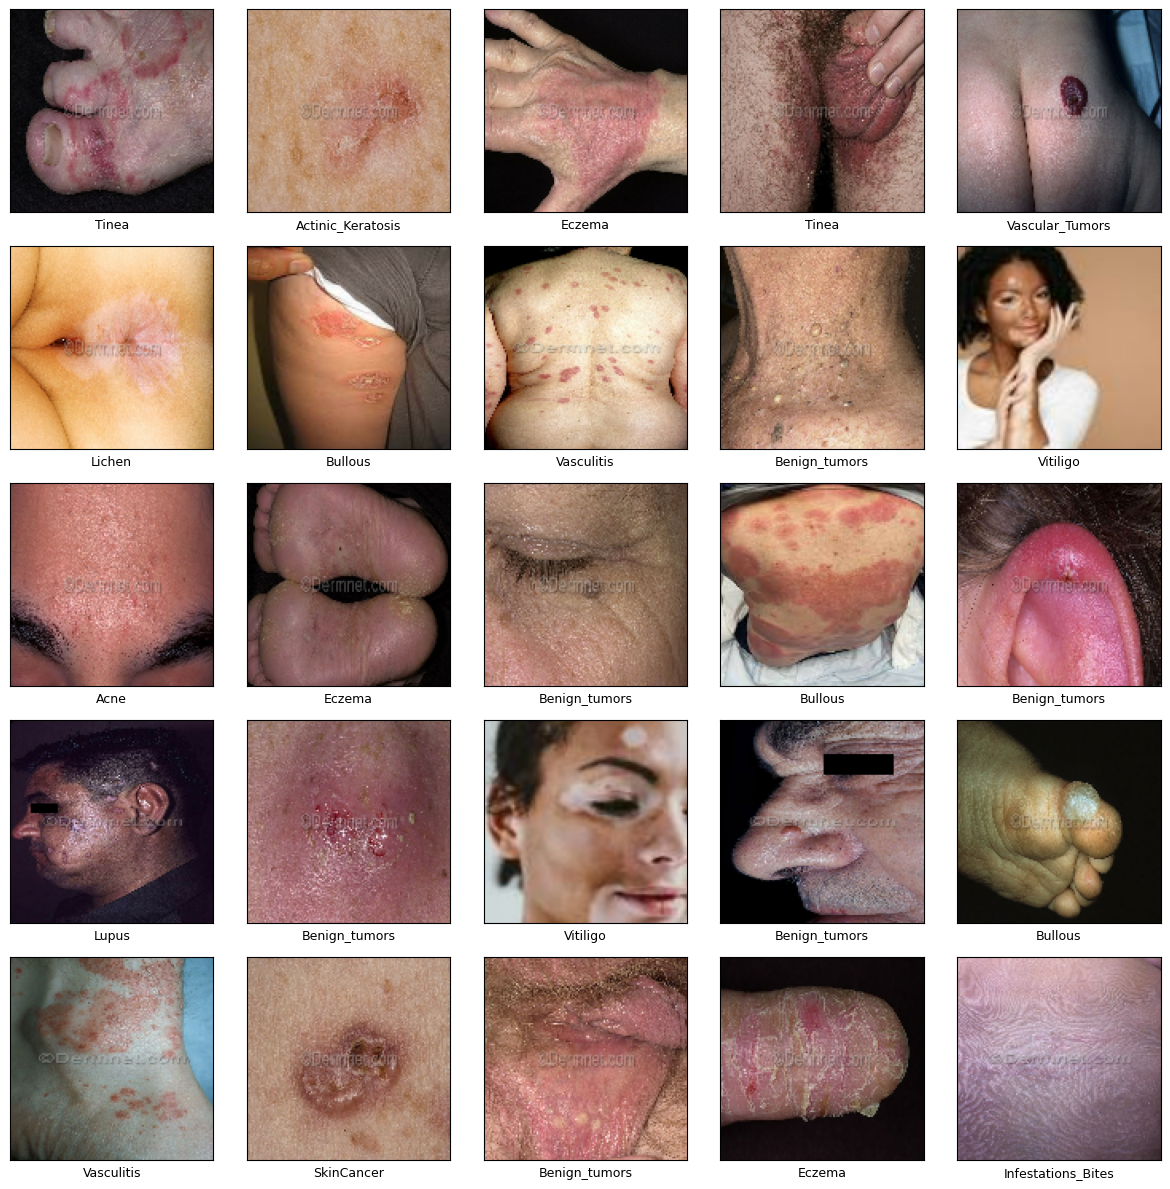

In [12]:
import matplotlib.pyplot as plt

# Extrair um lote de imagens para visualização
for imagens, rotulos in skin_train_ds.take(1):
    plt.figure(figsize=(12, 12))
    for i in range(min(25, len(imagens))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        # Converter a imagem de volta de float32 para o formato de exibição
        img = imagens[i].numpy().astype("uint8")
        plt.imshow(img)

        # Obter o rótulo correspondente utilizando os nomes originais em inglês
        classe_idx = int(rotulos[i].numpy())
        classe_nome = skin_class_names[classe_idx]
        plt.xlabel(classe_nome, fontsize=9)

    plt.tight_layout()
    plt.show()

In [13]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Carregando o modelo EfficientNetB0 pré-treinado
skin_base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

# Congelando os pesos do modelo base
skin_base_model.trainable = False

# Definindo a nova arquitetura para as 21 classes restantes com EfficientNetB0
skin_model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    skin_base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(21, activation="softmax")  # 21 classes após remoção do Unknown_Normal
])

skin_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

skin_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 21)             │         5,397 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,382,904 (16.72 MB)

 Trainable params: 333,333 (1.27 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [14]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. Extrair os rótulos de treino (y) para calcular o balanceamento
y_train = np.concatenate([labels.numpy() for _, labels in skin_train_ds])
classes = np.unique(y_train)

# 2. Calcular os pesos balanceados
weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

# 3. Criar o dicionário de pesos por classe
class_weights_dict = dict(zip(classes, weights))

print("Pesos calculados com sucesso para as 21 classes!")
for classe_idx, peso in class_weights_dict.items():
    print(f"{skin_class_names[classe_idx]}: {peso:.4f}")



Pesos calculados com sucesso para as 21 classes!
Acne: 0.9660
Actinic_Keratosis: 0.7908
Benign_tumors: 0.5236
Bullous: 1.1464
Candidiasis: 2.3684
DrugEruption: 1.0750
Eczema: 0.5649
Infestations_Bites: 1.1243
Lichen: 1.0485
Lupus: 1.8515
Moles: 1.6089
Psoriasis: 0.7336
Rosacea: 2.3213
Seborrh_Keratoses: 1.2889
SkinCancer: 0.8332
Sun_Sunlight_Damage: 1.8297
Tinea: 0.6288
Vascular_Tumors: 1.1030
Vasculitis: 1.2025
Vitiligo: 0.8672
Warts: 1.0077


In [15]:
skin_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Iniciando o treinamento do modelo de doenças de pele
skin_history = skin_model.fit(
    skin_train_ds,
    validation_data=skin_val_ds,
    epochs=15,
    callbacks=[skin_early_stop]
)

Epoch 1/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 350s 1s/step - accuracy: 0.2846 - loss: 2.3869 - val_accuracy: 0.5096 - val_loss: 1.6155
Epoch 2/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 306s 997ms/step - accuracy: 0.3898 - loss: 1.9898 - val_accuracy: 0.5815 - val_loss: 1.3781
Epoch 3/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 318s 1s/step - accuracy: 0.4451 - loss: 1.8051 - val_accuracy: 0.6268 - val_loss: 1.2631
Epoch 4/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 318s 1s/step - accuracy: 0.4924 - loss: 1.6621 - val_accuracy: 0.6272 - val_loss: 1.2360
Epoch 5/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 301s 965ms/step - accuracy: 0.5205 - loss: 1.5243 - val_accuracy: 0.6889 - val_loss: 1.0567
Epoch 6/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 319s 957ms/step - accuracy: 0.5455 - loss: 1.4447 - val_accuracy: 0.7293 - val_loss: 0.9596
Epoch 7/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 322s 954ms/step - accuracy: 0.5698 - loss: 1.3564 - val_accuracy: 0.7370 - val_loss: 0.9267
Epoch 8/15
307/307 ━━━━━━━━━━━━━━━━━━━━ 300s 978ms/step - accuracy: 0.5987 - loss: 1.

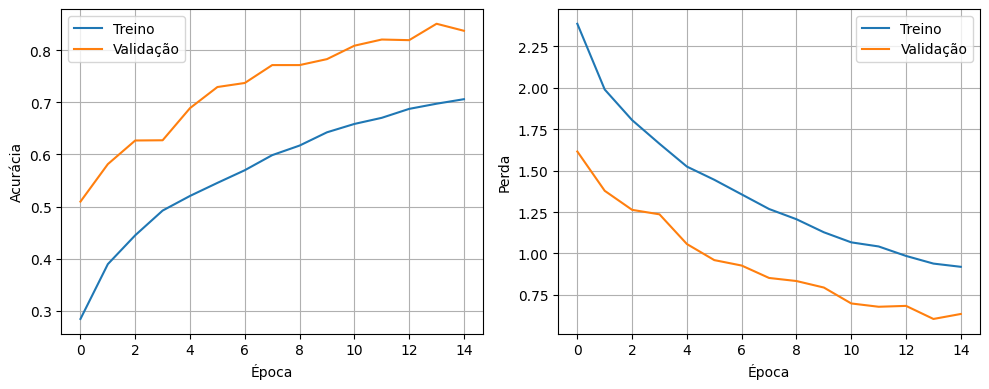

43/43 - 34s - 782ms/step - accuracy: 0.5247 - loss: 1.6402

Acurácia no conjunto de teste: 52.47%


In [16]:
import matplotlib.pyplot as plt

# Gerando os gráficos de desempenho do treinamento
plt.figure(figsize=(10, 4))

# Gráfico de Acurácia
plt.subplot(1, 2, 1)
plt.plot(skin_history.history['accuracy'], label='Treino')
plt.plot(skin_history.history['val_accuracy'], label='Validação')
plt.xlabel('Época')
plt.ylabel('Acurácia')
plt.legend(loc='best')
plt.grid(True)

# Gráfico de Perda (Loss)
plt.subplot(1, 2, 2)
plt.plot(skin_history.history['loss'], label='Treino')
plt.plot(skin_history.history['val_loss'], label='Validação')
plt.xlabel('Época')
plt.ylabel('Perda')
plt.legend(loc='best')
plt.grid(True)

plt.tight_layout()
plt.show()

# Avaliação final no conjunto de teste estruturado
test_loss, test_acc = skin_model.evaluate(skin_test_ds, verbose=2)
print(f"\nAcurácia no conjunto de teste: {test_acc * 100:.2f}%")

In [17]:
# Avaliando o modelo no conjunto de teste independente de doenças de pele
skin_test_loss, skin_test_accuracy = skin_model.evaluate(skin_test_ds)

print(f"\nPerda no Teste (Skin Disease): {skin_test_loss:.4f}")
print(f"Acurácia no Teste (Skin Disease): {skin_test_accuracy * 100:.2f}%")

43/43 ━━━━━━━━━━━━━━━━━━━━ 32s 750ms/step - accuracy: 0.5247 - loss: 1.6402

Perda no Teste (Skin Disease): 1.6402
Acurácia no Teste (Skin Disease): 52.47%


=== RELATÓRIO DE CLASSIFICAÇÃO (Skin Disease) ===
                     precision    recall  f1-score   support

               Acne     0.6463    0.8154    0.7211        65
  Actinic_Keratosis     0.5093    0.6627    0.5759        83
      Benign_tumors     0.4235    0.5950    0.4948       121
            Bullous     0.5102    0.4545    0.4808        55
        Candidiasis     0.5833    0.5185    0.5490        27
       DrugEruption     0.6400    0.5246    0.5766        61
             Eczema     0.5644    0.5089    0.5352       112
 Infestations_Bites     0.4500    0.3000    0.3600        60
             Lichen     0.4898    0.3934    0.4364        61
              Lupus     0.4444    0.2353    0.3077        34
              Moles     0.5455    0.4500    0.4932        40
          Psoriasis     0.4565    0.4773    0.4667        88
            Rosacea     0.4222    0.6786    0.5205        28
  Seborrh_Keratoses     0.6944    0.4902    0.5747        51
         SkinCancer     0.4605    

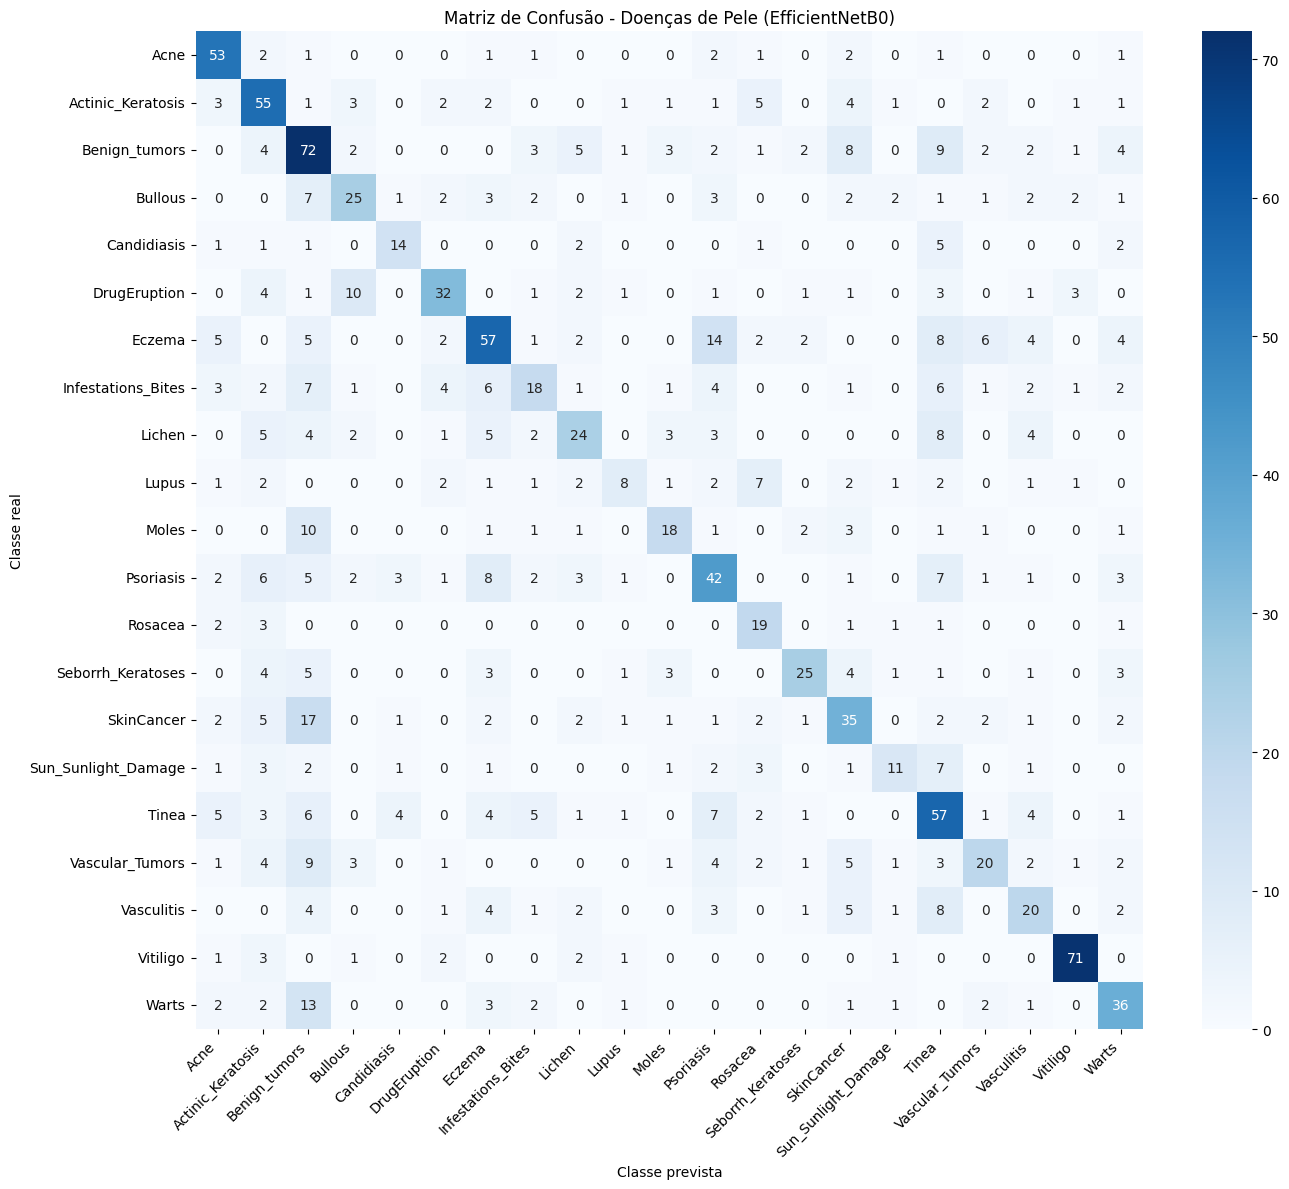

In [18]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Obter as classes reais (rótulos inteiros) do dataset de teste atual
y_true = np.concatenate([
    labels.numpy() for _, labels in skin_test_ds
])

# 2. Usar o nome correto do modelo ativo: skin_model
y_prob = skin_model.predict(skin_test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# 3. Exibir o Relatório de Classificação
print("=== RELATÓRIO DE CLASSIFICAÇÃO (Skin Disease) ===")
print(classification_report(
    y_true,
    y_pred,
    target_names=skin_class_names,
    digits=4
))

# 4. Calcular a matriz de confusão
cm = confusion_matrix(y_true, y_pred)

# 5. Plotar a matriz de confusão modificada
plt.figure(figsize=(14, 12))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=skin_class_names,
    yticklabels=skin_class_names
)

plt.title("Matriz de Confusão - Doenças de Pele (EfficientNetB0)")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

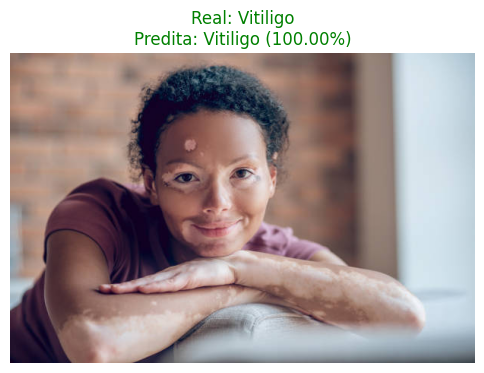

Arquivo: cute-young-woman-with-pigmentation-on-her-face-looking-candid-and-sweet.jpeg
Classe real: Vitiligo
Classe prevista: Vitiligo
Confiança: 100.00%
Resultado: ACERTOU

Probabilidades por classe:
Acne: 0.00%
Actinic_Keratosis: 0.00%
Benign_tumors: 0.00%
Bullous: 0.00%
Candidiasis: 0.00%
DrugEruption: 0.00%
Eczema: 0.00%
Infestations_Bites: 0.00%
Lichen: 0.00%
Lupus: 0.00%
Moles: 0.00%
Psoriasis: 0.00%
Rosacea: 0.00%
Seborrh_Keratoses: 0.00%
SkinCancer: 0.00%
Sun_Sunlight_Damage: 0.00%
Tinea: 0.00%
Vascular_Tumors: 0.00%
Vasculitis: 0.00%
Vitiligo: 100.00%
Warts: 0.00%


In [19]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array

# Garantir que as class_names estejam atualizadas com as 21 classes do dataset atual
class_names = skin_class_names

# Escolhemos uma classe existente no seu diretório de testes filtrado para testar
classe = "Vitiligo"
pasta = os.path.join(filtered_test_dir, classe)

arquivos = [
    nome for nome in os.listdir(pasta)
    if nome.lower().endswith((".jpg", ".jpeg", ".png"))
]

if not arquivos:
    raise ValueError(f"Nenhuma imagem encontrada na pasta: {pasta}")

nome_imagem = random.choice(arquivos)
caminho_imagem = os.path.join(pasta, nome_imagem)

# Carregar a imagem no tamanho esperado pelo seu modelo atual (128, 128)
img = load_img(
    caminho_imagem,
    target_size=(128, 128),
    color_mode="rgb"
)
img_array = img_to_array(img)

# Expandir dimensões para entrada no modelo
entrada = np.expand_dims(img_array, axis=0)

# Fazer a predição usando o modelo correto: skin_model
predicao = skin_model.predict(entrada, verbose=0)[0]

indice_predito = np.argmax(predicao)
classe_predita = class_names[indice_predito]
confianca = predicao[indice_predito] * 100

plt.figure(figsize=(6, 6))
plt.imshow(load_img(caminho_imagem))
plt.axis("off")
plt.title(
    f"Real: {classe}\n"
    f"Predita: {classe_predita} ({confianca:.2f}%)",
    color="green" if classe == classe_predita else "red"
)
plt.show()

print("Arquivo:", nome_imagem)
print("Classe real:", classe)
print("Classe prevista:", classe_predita)
print(f"Confiança: {confianca:.2f}%")
print("Resultado:", "ACERTOU" if classe == classe_predita else "ERROU")

print("\nProbabilidades por classe:")
for nome, probabilidade in zip(class_names, predicao):
    print(f"{nome}: {probabilidade * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_238
Received: inputs=['Tensor(shape=(5, 128, 128, 3))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_238
Received: inputs=['Tensor(shape=(50, 128, 128, 3))']
  warnings.warn(msg)


Classe prevista: Infestations_Bites, Classe real: Acne


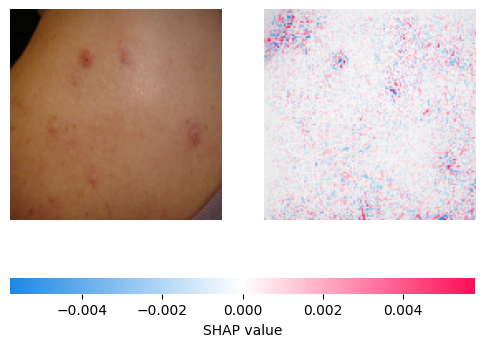

Classe prevista: Actinic_Keratosis, Classe real: Actinic_Keratosis


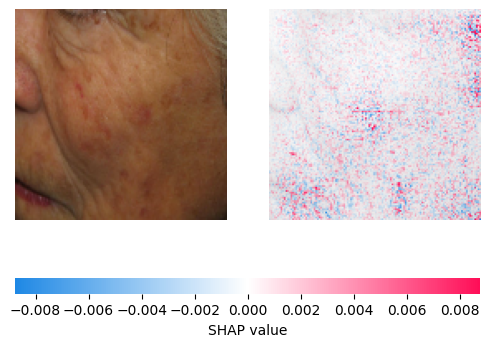

Classe prevista: Benign_tumors, Classe real: Benign_tumors


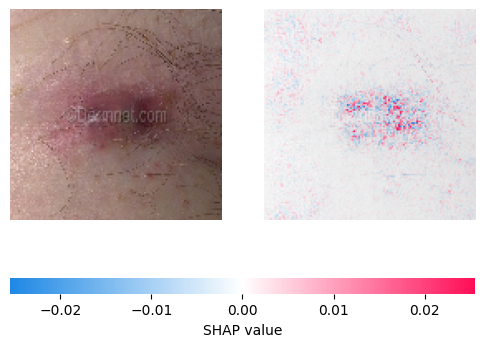

Classe prevista: Bullous, Classe real: Bullous


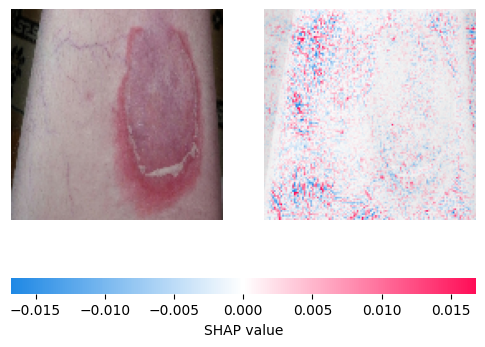

Classe prevista: Tinea, Classe real: Candidiasis


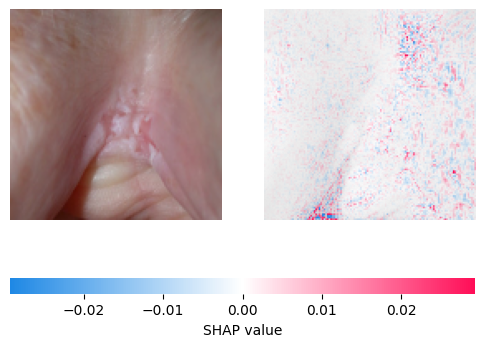

In [20]:
# Instalar o SHAP se não estiver presente no ambiente
!pip install -q shap

import shap
import numpy as np

# Preparando dados de fundo (background) para o explicador
background = np.concatenate(
    [x.numpy() for x, y in skin_train_ds.take(3)],
    axis=0
)[:50]

# Escolher uma amostra de cada uma das 5 primeiras classes encontradas no conjunto de teste
amostras, rotulos, vistos = [], [], set()
for imgs, lbls in skin_test_ds:
    for img, lbl in zip(imgs.numpy(), lbls.numpy()):
        c = int(lbl)
        if c not in vistos:
            vistos.add(c)
            amostras.append(img)
            rotulos.append(c)
        if len(vistos) == 5:
            break
    if len(vistos) == 5:
        break

test_sample = np.array(amostras)
test_labels = np.array(rotulos)

# Fazer previsões nas amostras selecionadas
preds = skin_model.predict(test_sample, verbose=0)
pred_classes = np.argmax(preds, axis=1)
real_classes = test_labels

# Criar o GradientExplainer para o nosso modelo
explainer = shap.GradientExplainer(skin_model, background)
shap_values = explainer.shap_values(test_sample)

# Visualizar as explicações SHAP para cada uma das amostras
for i in range(len(test_sample)):
    print(
        f"Classe prevista: {skin_class_names[pred_classes[i]]}, "
        f"Classe real: {skin_class_names[real_classes[i]]}"
    )

    if isinstance(shap_values, list):
        valores_imagem = shap_values[pred_classes[i]][i:i+1]
    else:
        valores = np.asarray(shap_values)
        if valores.ndim == 5:
            valores_imagem = valores[i:i+1, ..., pred_classes[i]]
        elif valores.ndim == 4:
            valores_imagem = valores[i:i+1]
        else:
            raise ValueError(f"Formato SHAP inesperado: {valores.shape}")

    # Como usamos EfficientNet que recebe imagens sem decréscimo de canal de cor,
    # apenas garantimos o tipo uint8 correto sem inversão de canais desnecessária.
    imagem_exibicao = test_sample[i:i+1].copy().astype(np.uint8)

    shap.image_plot(
        [valores_imagem],
        imagem_exibicao
    )

# Nova seção